# 03 · Exploratory Data Analysis
**Netflix Content Analytics — Phase 3**

Time for the fun part. We'll answer **10 questions**, each with:
1. 🎯 **The question** and why it matters
2. 💻 **The code** that computes the answer
3. 📊 **A chart** chosen for that question
4. 🔍 **What we found**, in plain language, plus a ⚠️ **caveat** where needed

**Ground rules for honest analysis**
- We describe the **catalog** (what's available), not **performance** (what's watched). No viewing data exists here.
- The data was captured around **September 2021** — 2021 is a **partial year**.
- It is a **snapshot**: titles that were added and later removed before 2021 are not in the file, so
  earlier years are probably undercounted (survivorship bias).

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
from pathlib import Path

PROCESSED_DIR = Path("..") / "data" / "processed"
FIGURES_DIR = Path("..") / "reports" / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

titles = pd.read_csv(PROCESSED_DIR / "netflix_titles_clean.csv", parse_dates=["date_added"])
title_countries = pd.read_csv(PROCESSED_DIR / "netflix_title_countries.csv")
title_genres = pd.read_csv(PROCESSED_DIR / "netflix_title_genres.csv")

# Nullable integers for the date-derived columns (missing dates stay missing)
for column in ["added_year", "added_month", "content_age_at_add"]:
    titles[column] = titles[column].astype("Int64")

print(f"titles: {len(titles):,} | title_countries: {len(title_countries):,} | title_genres: {len(title_genres):,}")

titles: 8,806 | title_countries: 10,842 | title_genres: 19,320


### A consistent visual style
Every chart uses the **same two colours for the same two things** — Netflix red for Movies, steel blue for
TV Shows — so readers never have to re-learn the legend. Single-series charts use neutral grey, with red only
to highlight what matters. One helper saves every chart for the README.

In [2]:
NETFLIX_RED = "#E50914"
TV_BLUE = "#2E5A88"
NEUTRAL = "#6B6B6B"
TYPE_COLORS = {"Movie": NETFLIX_RED, "TV Show": TV_BLUE}

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titleweight": "bold", "axes.titlesize": 13, "axes.titlelocation": "left",
    "grid.color": "#E6E6E6",
})

def save(fig, name):
    """Save a figure to reports/figures so the README can embed it."""
    fig.savefig(FIGURES_DIR / f"{name}.png")

---
## Q1 · How many movies and TV shows are in the catalog?
🎯 The most basic KPI — and the denominator for everything else.

In [3]:
type_counts = titles["type"].value_counts()
type_share = titles["type"].value_counts(normalize=True).mul(100).round(1)
summary_q1 = pd.DataFrame({"titles": type_counts, "share_pct": type_share})
print(f"Total titles: {len(titles):,}")
summary_q1

Total titles: 8,806


,titles,share_pct
type,,
Movie,6130,69.6
TV Show,2676,30.4


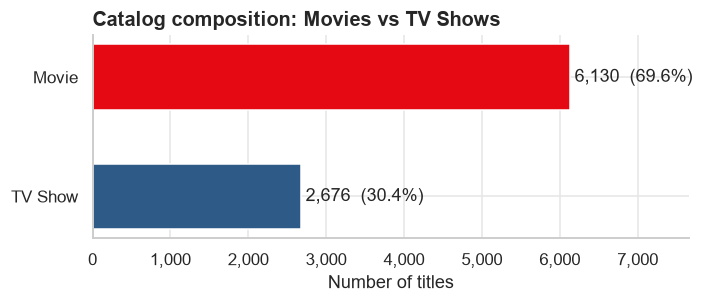

In [4]:
fig, ax = plt.subplots(figsize=(7, 2.4))
bars = ax.barh(summary_q1.index, summary_q1["titles"], color=[TYPE_COLORS[t] for t in summary_q1.index], height=0.55)
for bar, (count, pct) in zip(bars, summary_q1.itertuples(index=False)):
    ax.text(bar.get_width() + 60, bar.get_y() + bar.get_height() / 2, f"{count:,}  ({pct}%)", va="center")
ax.invert_yaxis()
ax.set_xlim(0, type_counts.max() * 1.25)
ax.set_title("Catalog composition: Movies vs TV Shows")
ax.set_xlabel("Number of titles")
ax.xaxis.set_major_formatter(mticker.StrMethodFormatter("{x:,.0f}"))
save(fig, "q1_movies_vs_tv")
plt.show()

🔍 **Finding:** Movies make up roughly **7 in 10** titles; TV shows about **3 in 10**.

⚠️ **Caveat:** one TV show can contain dozens of hours of content. Counting *titles* is not the same as
counting *hours*, so "more movies" does not mean "more viewing time is movies".

💡 *Why a bar chart and not a pie?* Two values are easy either way, but bars stay readable when there are many
categories, and comparing lengths is easier for people than comparing angles.

---
## Q2 · How has the release-year distribution changed?
🎯 Is the catalog mostly new content, or a library of older titles?

In [5]:
release_decade = (titles["release_year"] // 10 * 10).value_counts().sort_index()
print("Titles by release decade:\n", release_decade.to_string())
print(f"\nReleased 2010 or later: {(titles['release_year'] >= 2010).mean():.1%}")
print(f"Released 2015 or later: {(titles['release_year'] >= 2015).mean():.1%}")
print(f"Oldest title: {titles['release_year'].min()} | Median release year: {titles['release_year'].median():.0f}")

Titles by release decade:
 release_year
1920       1
1940      15
1950      11
1960      25
1970      70
1980     129
1990     274
2000     810
2010    5926
2020    1545

Released 2010 or later: 84.8%
Released 2015 or later: 70.6%
Oldest title: 1925 | Median release year: 2017


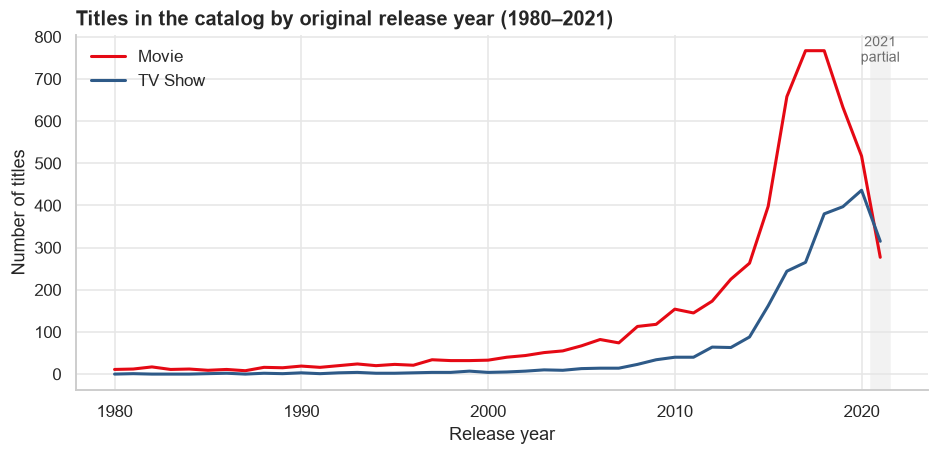

In [6]:
release_by_type = (
    titles.query("release_year >= 1980")
    .groupby(["release_year", "type"]).size().unstack(fill_value=0)
)

fig, ax = plt.subplots(figsize=(10, 4.2))
for content_type in ["Movie", "TV Show"]:
    ax.plot(release_by_type.index, release_by_type[content_type], color=TYPE_COLORS[content_type],
            linewidth=2, label=content_type)
ax.axvspan(2020.5, 2021.5, color="#F2F2F2", zorder=0)
ax.text(2021, ax.get_ylim()[1] * 0.92, "2021\npartial", ha="center", fontsize=9, color=NEUTRAL)
ax.set_title("Titles in the catalog by original release year (1980–2021)")
ax.set_xlabel("Release year")
ax.set_ylabel("Number of titles")
ax.legend(frameon=False)
save(fig, "q2_release_year_by_type")
plt.show()

🔍 **Finding:** The catalog is overwhelmingly **recent**: about **85%** of titles were released in 2010 or later,
and the median release year is 2017. Movies peak around 2017–2018 releases. TV-show releases rise through 2020, and
for 2021 releases TV shows actually **outnumber** movies.

⚠️ **Caveats:** (1) 2021 is partial. (2) For TV shows, `release_year` may reflect the most recent season,
which would push TV titles toward recent years. (3) It's a snapshot — older titles may have been removed.

---
## Q3 · How many titles were added to Netflix each year?
🎯 How fast did the catalog grow? This uses `added_year` (when it arrived on Netflix), not when it was made.

In [7]:
additions_by_year = titles.groupby("added_year").size().rename("titles_added").to_frame()
additions_by_year["yoy_change_pct"] = additions_by_year["titles_added"].pct_change().mul(100).round(1)
additions_by_year

,titles_added,yoy_change_pct
added_year,,
2008,2,NaN
2009,2,0.0
2010,1,-50.0
2011,13,1200.0
2012,3,-76.9
2013,11,266.7
2014,24,118.2
2015,82,241.7
2016,429,423.2


The raw numbers suggest additions **fell** in 2020 and 2021. But 2021 only runs to September!
A fair comparison uses the **same months** each year — this is called a *year-to-date (YTD)* comparison.

In [8]:
LAST_MONTH = int(titles.loc[titles["added_year"] == 2021, "added_month"].max())
ytd_additions = (
    titles[titles["added_month"] <= LAST_MONTH]
    .groupby("added_year").size()
    .loc[2017:]
    .rename(f"titles_added_jan_to_month_{LAST_MONTH}")
)
ytd_additions.to_frame()

,titles_added_jan_to_month_9
added_year,
2017,859
2018,1119
2019,1353
2020,1389
2021,1498


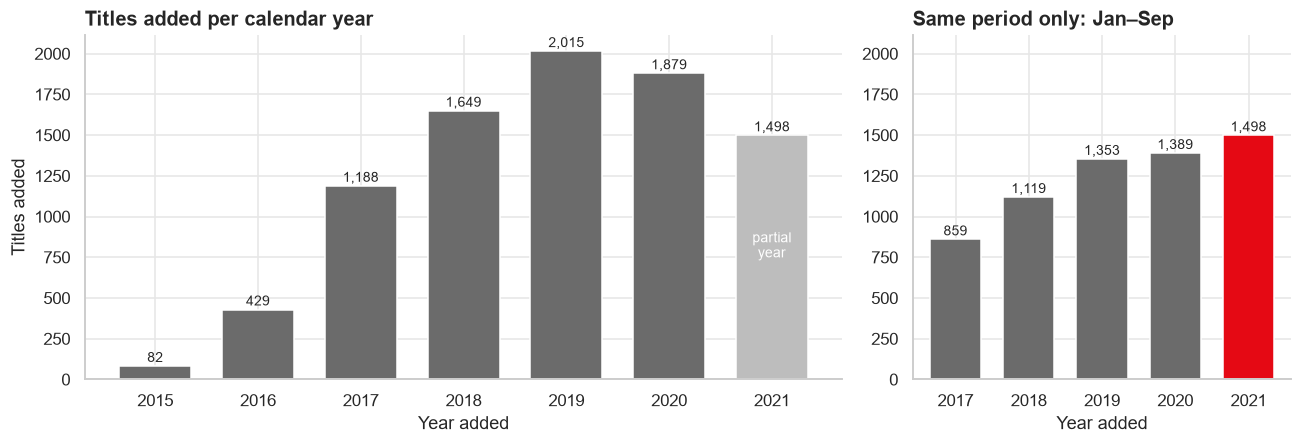

In [9]:
fig, (ax_full, ax_ytd) = plt.subplots(1, 2, figsize=(12, 4.2), gridspec_kw={"width_ratios": [2, 1]})

years = additions_by_year.loc[2015:].index.astype(int)
values = additions_by_year.loc[2015:, "titles_added"]
bar_colors = [NEUTRAL if y < 2021 else "#BDBDBD" for y in years]
ax_full.bar(years, values, color=bar_colors, width=0.7)
for x, v in zip(years, values):
    ax_full.text(x, v + 25, f"{v:,}", ha="center", fontsize=9)
ax_full.text(2021, values.iloc[-1] / 2, "partial\nyear", ha="center", fontsize=9, color="white")
ax_full.set_title("Titles added per calendar year")
ax_full.set_xlabel("Year added")
ax_full.set_ylabel("Titles added")

ytd_years = ytd_additions.index.astype(int)
ax_ytd.bar(ytd_years, ytd_additions.values,
           color=[NETFLIX_RED if y == 2021 else NEUTRAL for y in ytd_years], width=0.7)
for x, v in zip(ytd_years, ytd_additions.values):
    ax_ytd.text(x, v + 25, f"{v:,}", ha="center", fontsize=9)
ax_ytd.set_title(f"Same period only: Jan–{pd.Timestamp(2021, LAST_MONTH, 1):%b}")
ax_ytd.set_xlabel("Year added")
ax_ytd.set_ylim(ax_full.get_ylim())
fig.tight_layout()
save(fig, "q3_additions_per_year")
plt.show()

🔍 **Finding:** Additions jumped from double digits before 2015 to well over a thousand a year from 2017.
**2019** is the largest full year in this snapshot. The apparent "decline" in 2021 is mostly a **partial-year
artefact**: comparing the same January–September window, 2021 had **more** additions than 2019 or 2020.

⚠️ **Caveat:** Because the file is a 2021 snapshot, titles added in early years and later removed are missing —
so the steep early growth is partly real growth and partly survivorship bias. We can't separate the two with
this data.

🧠 **Analyst lesson:** always check whether the latest period is complete before declaring a trend.

---
## Q4 · Which countries have the highest number of titles?
🎯 Where does the catalog's content come from?

We use the **bridge table** (one row per title–country), so a US–India co-production counts for *both*
countries. That means country counts add up to **more** than the number of titles — this is expected.

In [10]:
country_type = (
    title_countries.merge(titles[["show_id", "type"]], on="show_id")
    .groupby(["country", "type"]).size().unstack(fill_value=0)
)
country_type["total"] = country_type.sum(axis=1)
country_type["tv_share_pct"] = (country_type["TV Show"] / country_type["total"] * 100).round(1)
country_type["share_of_catalog_pct"] = (country_type["total"] / len(titles) * 100).round(1)

top_countries = country_type.drop(index="Unknown").sort_values("total", ascending=False).head(10)
print(f"'Unknown' country: {country_type.loc['Unknown', 'total']:,} titles "
      f"({country_type.loc['Unknown', 'share_of_catalog_pct']}% of catalog)")
top_countries

'Unknown' country: 831 titles (9.4% of catalog)


type,Movie,TV Show,total,tv_share_pct,share_of_catalog_pct
country,,,,,
United States,2752,938,3690,25.4,41.9
India,962,84,1046,8.0,11.9
United Kingdom,534,272,806,33.7,9.2
Canada,319,126,445,28.3,5.1
France,303,90,393,22.9,4.5
Japan,119,199,318,62.6,3.6
Spain,171,61,232,26.3,2.6
South Korea,61,170,231,73.6,2.6
Germany,182,44,226,19.5,2.6


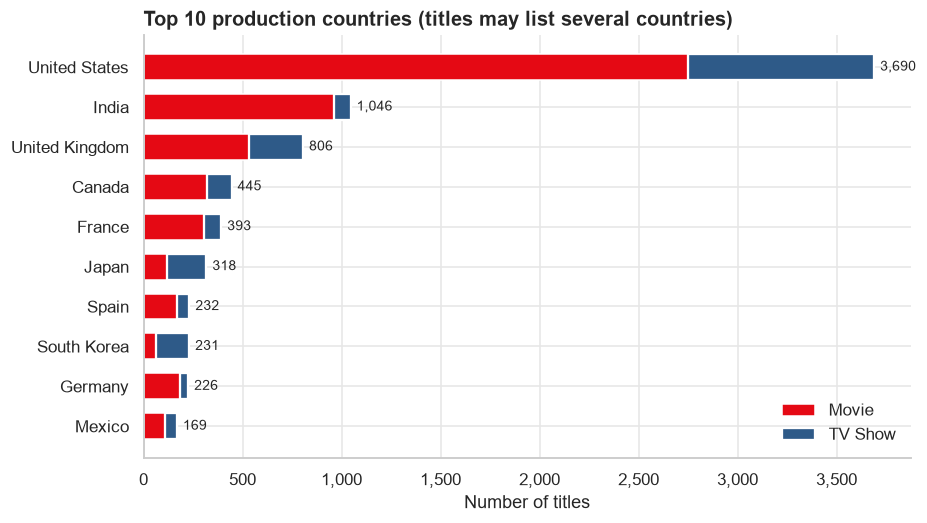

In [11]:
fig, ax = plt.subplots(figsize=(9, 5))
plot_data = top_countries.iloc[::-1]
ax.barh(plot_data.index, plot_data["Movie"], color=NETFLIX_RED, label="Movie", height=0.65)
ax.barh(plot_data.index, plot_data["TV Show"], left=plot_data["Movie"], color=TV_BLUE, label="TV Show",
        height=0.65, edgecolor="white", linewidth=1.5)
for y, total in enumerate(plot_data["total"]):
    ax.text(total + 30, y, f"{total:,}", va="center", fontsize=9)
ax.set_title("Top 10 production countries (titles may list several countries)")
ax.set_xlabel("Number of titles")
ax.xaxis.set_major_formatter(mticker.StrMethodFormatter("{x:,.0f}"))
ax.legend(frameon=False, loc="lower right")
save(fig, "q4_top_countries")
plt.show()

🔍 **Finding:** The **United States** is linked to about **42%** of all titles — far ahead of **India** and the
**United Kingdom**. The country mix also differs by type: India's titles are overwhelmingly **movies**, while
**Japan** and **South Korea** lean towards **TV shows** (anime and K-dramas).

⚠️ **Caveat:** about **9%** of titles have no country recorded, and "country" means production country — not
where the title is available or watched.

---
## Q5 · Which genres or listed categories appear most frequently?
🎯 What kinds of content dominate the catalog?

Two views: the **raw Netflix labels**, and our **genre groups** that merge movie/TV variants
("Dramas" + "TV Dramas" → Drama) and set aside non-genre labels like "International Movies".

In [12]:
raw_label_counts = title_genres["genre"].value_counts().head(10)
print("Top raw Netflix labels:\n", raw_label_counts.to_string())

international_share = (
    title_genres.loc[title_genres["genre_group"] == "International (label)", "show_id"].nunique() / len(titles)
)
print(f"\nTitles tagged with an 'International' label: {international_share:.1%}")

Top raw Netflix labels:
 genre
International Movies        2751
Dramas                      2426
Comedies                    1674
International TV Shows      1351
Documentaries                869
Action & Adventure           859
TV Dramas                    763
Independent Movies           756
Children & Family Movies     641
Romantic Movies              616

Titles tagged with an 'International' label: 46.6%


In [13]:
genre_group_counts = (
    title_genres[~title_genres["genre_group"].str.contains("(label)", regex=False)]
    .groupby("genre_group")["show_id"].nunique()
    .sort_values(ascending=False)
)
genre_group_share = (genre_group_counts / len(titles) * 100).round(1)
pd.DataFrame({"titles": genre_group_counts, "pct_of_catalog": genre_group_share}).head(12)

,titles,pct_of_catalog
genre_group,,
Drama,3189,36.2
Comedy,2255,25.6
Documentary,1268,14.4
Kids & Family,1092,12.4
Action & Adventure,1027,11.7
Romance,986,11.2
Independent,756,8.6
Thriller & Mystery,723,8.2
Crime,470,5.3


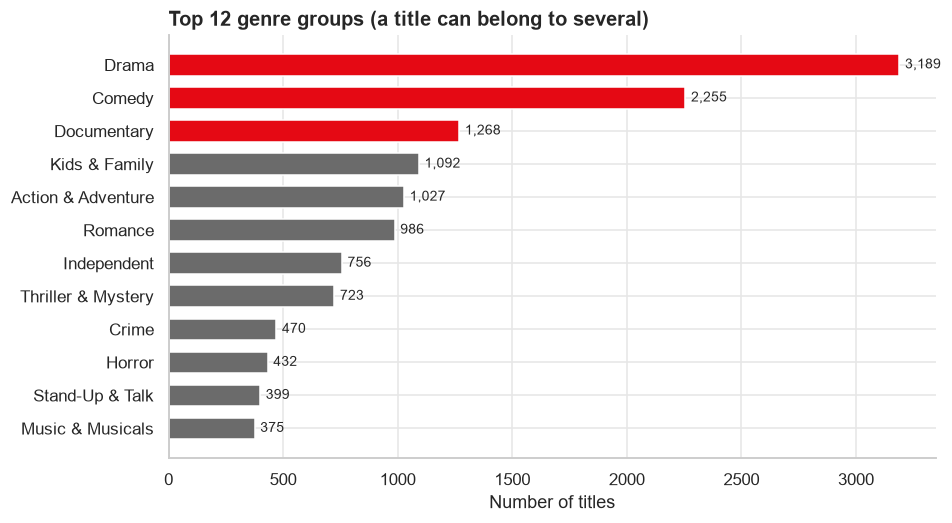

In [14]:
top_genres = genre_group_counts.head(12).iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 5))
colors = [NETFLIX_RED if g in genre_group_counts.head(3).index else NEUTRAL for g in top_genres.index]
ax.barh(top_genres.index, top_genres.values, color=colors, height=0.65)
for y, v in enumerate(top_genres.values):
    ax.text(v + 25, y, f"{v:,}", va="center", fontsize=9)
ax.set_title("Top 12 genre groups (a title can belong to several)")
ax.set_xlabel("Number of titles")
save(fig, "q5_top_genres")
plt.show()

🔍 **Finding:** "International Movies" is the single most frequent raw label, and nearly **half** of all titles
carry an "International" tag — the catalog is strongly global. Among real genres, **Drama** leads clearly,
followed by **Comedy** and **Documentary**.

⚠️ **Caveat:** genres are Netflix's own categories, and titles have several, so percentages add to more than 100%.

---
## Q6 · What are the most common content ratings?
🎯 Who is the catalog aimed at — kids, families, teens or adults?

In [15]:
rating_counts = titles["rating"].value_counts()
rating_counts.to_frame("titles").T

rating,TV-MA,TV-14,TV-PG,R,PG-13,TV-Y7,TV-Y,PG,TV-G,NR,G,Unknown,TV-Y7-FV,NC-17,UR
titles,3206,2160,863,799,490,334,307,287,220,80,41,7,6,3,3


In [16]:
AUDIENCE_ORDER = ["Kids", "Family", "Teens", "Adults", "Not Rated"]
audience_by_type = pd.crosstab(titles["type"], titles["audience_group"], normalize="index").mul(100).round(1)[AUDIENCE_ORDER]
audience_by_type

audience_group,Kids,Family,Teens,Adults,Not Rated
type,,,,,
Movie,4.5,16.2,31.3,46.7,1.4
TV Show,13.9,15.6,27.4,42.9,0.3


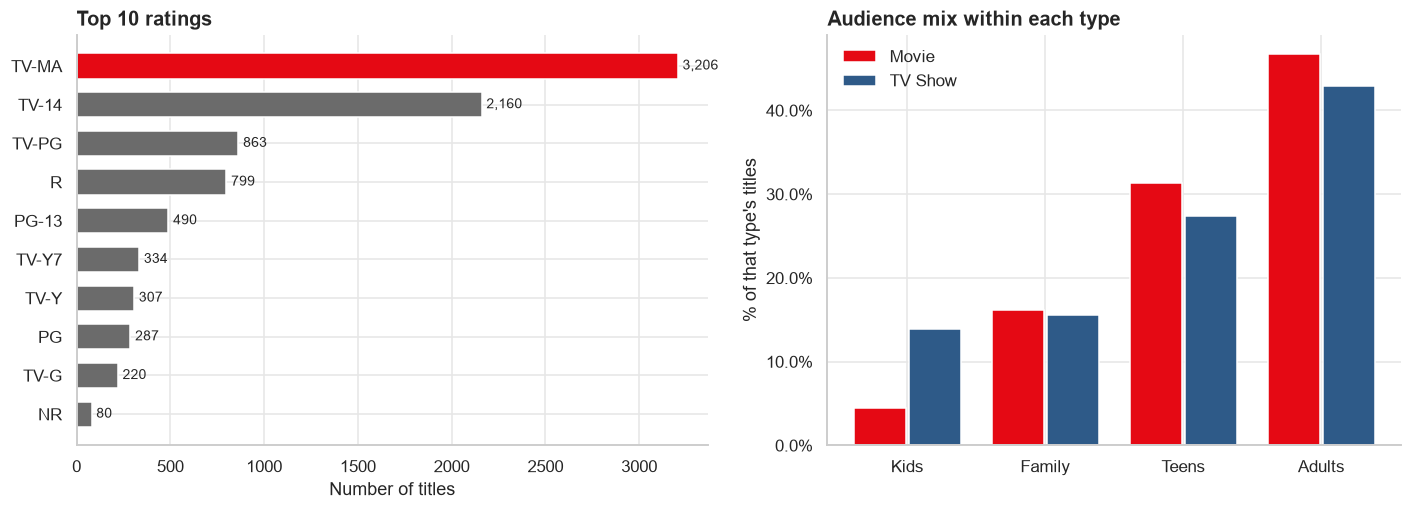

In [17]:
fig, (ax_rating, ax_aud) = plt.subplots(1, 2, figsize=(13, 4.8), gridspec_kw={"width_ratios": [1.1, 1]})

top_ratings = rating_counts.head(10).iloc[::-1]
ax_rating.barh(top_ratings.index, top_ratings.values,
               color=[NETFLIX_RED if r == "TV-MA" else NEUTRAL for r in top_ratings.index], height=0.65)
for y, v in enumerate(top_ratings.values):
    ax_rating.text(v + 25, y, f"{v:,}", va="center", fontsize=9)
ax_rating.set_title("Top 10 ratings")
ax_rating.set_xlabel("Number of titles")

audience_plot = audience_by_type.drop(columns="Not Rated").T
x = np.arange(len(audience_plot))
ax_aud.bar(x - 0.2, audience_plot["Movie"], width=0.38, color=NETFLIX_RED, label="Movie")
ax_aud.bar(x + 0.2, audience_plot["TV Show"], width=0.38, color=TV_BLUE, label="TV Show")
ax_aud.set_xticks(x, audience_plot.index)
ax_aud.yaxis.set_major_formatter(mticker.PercentFormatter())
ax_aud.set_title("Audience mix within each type")
ax_aud.set_ylabel("% of that type's titles")
ax_aud.legend(frameon=False)
fig.tight_layout()
save(fig, "q6_ratings")
plt.show()

🔍 **Finding:** **TV-MA** (mature audiences) is the most common rating, followed by **TV-14**. Grouped into
audiences, **adult** content is the largest band for both movies and TV shows. The biggest difference between
types is **kids** content, which makes up a noticeably larger share of TV shows than of movies.

⚠️ **Caveat:** the audience bands are *our* grouping of US rating codes; Netflix's own maturity system may differ.

---
## Q7 · How do movie durations vary?
🎯 What's a "typical" Netflix movie length? We look at the **median** (middle value), which isn't pulled by
extreme outliers the way the mean is.

In [18]:
movie_minutes = titles.loc[titles["type"] == "Movie", "duration_value"]
print(movie_minutes.describe().round(1).to_string())
print(f"\nShare between 60 and 120 minutes: {movie_minutes.between(60, 120).mean():.1%}")
print(f"Under 60 minutes (shorts, specials): {(movie_minutes < 60).sum():,}")
print(f"Over 150 minutes: {(movie_minutes > 150).sum():,}")

count    6130.0
mean       99.6
std        28.3
min         3.0
25%        87.0
50%        98.0
75%       114.0
max       312.0

Share between 60 and 120 minutes: 73.9%
Under 60 minutes (shorts, specials): 458
Over 150 minutes: 245


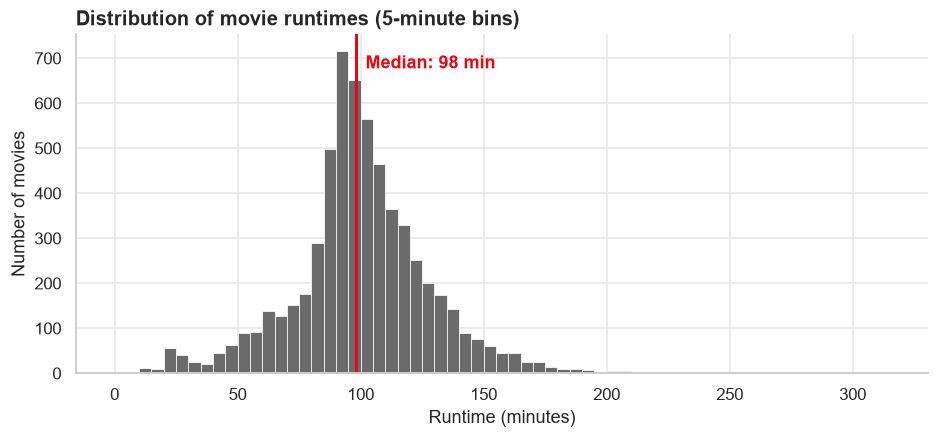

In [19]:
fig, ax = plt.subplots(figsize=(10, 4))
ax.hist(movie_minutes, bins=range(0, 320, 5), color=NEUTRAL, edgecolor="white", linewidth=0.5)
median_minutes = movie_minutes.median()
ax.axvline(median_minutes, color=NETFLIX_RED, linewidth=2)
ax.text(median_minutes + 4, ax.get_ylim()[1] * 0.9, f"Median: {median_minutes:.0f} min", color=NETFLIX_RED,
        fontweight="bold")
ax.set_title("Distribution of movie runtimes (5-minute bins)")
ax.set_xlabel("Runtime (minutes)")
ax.set_ylabel("Number of movies")
save(fig, "q7_movie_durations")
plt.show()

🔍 **Finding:** The typical movie runs about **1.5–2 hours** (median ≈ **98 minutes**), and roughly **three in
four** movies fall between 60 and 120 minutes. There is a long tail on both sides: short films and comedy
specials under an hour, and a few epics over 2½ hours.

---
## Q8 · How many seasons do TV shows typically have?

In [20]:
tv_seasons = titles.loc[titles["type"] == "TV Show", "duration_value"]
season_bucket = tv_seasons.clip(upper=6).map(lambda s: f"{s}" if s < 6 else "6+")
season_dist = season_bucket.value_counts().reindex(["1", "2", "3", "4", "5", "6+"])
season_share = (season_dist / season_dist.sum() * 100).round(1)
print(f"Median seasons: {tv_seasons.median():.0f} | Mean: {tv_seasons.mean():.2f} | Max: {tv_seasons.max()}")
pd.DataFrame({"shows": season_dist, "share_pct": season_share})

Median seasons: 1 | Mean: 1.76 | Max: 17


,shows,share_pct
duration_value,,
1,1793,67.0
2,425,15.9
3,199,7.4
4,95,3.6
5,65,2.4
6+,99,3.7


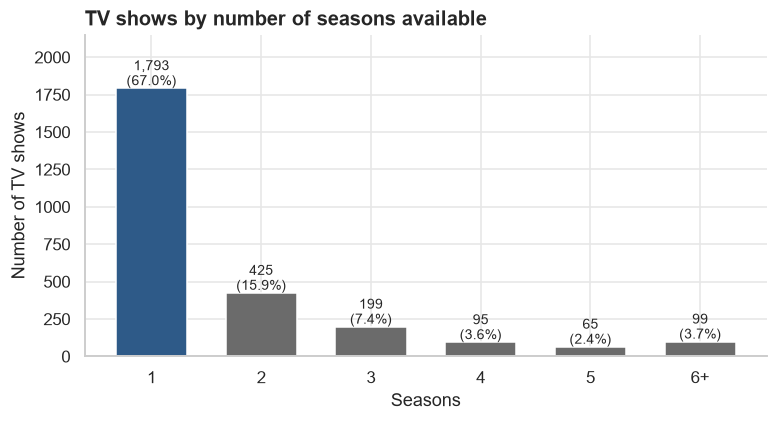

In [21]:
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.bar(season_dist.index, season_dist.values,
       color=[TV_BLUE if s == "1" else NEUTRAL for s in season_dist.index], width=0.65)
for x, (v, p) in enumerate(zip(season_dist.values, season_share.values)):
    ax.text(x, v + 20, f"{v:,}\n({p}%)", ha="center", fontsize=9)
ax.set_ylim(0, season_dist.max() * 1.2)
ax.set_title("TV shows by number of seasons available")
ax.set_xlabel("Seasons")
ax.set_ylabel("Number of TV shows")
save(fig, "q8_tv_seasons")
plt.show()

🔍 **Finding:** About **two-thirds** of TV shows have just **one season** available; the median is 1.
Long-running shows (6+ seasons) are a small minority.

⚠️ **Caveat:** this is seasons *available on Netflix* at snapshot time — not necessarily seasons produced.
A one-season show may be new, a limited series, cancelled, or only partly licensed. We can't tell which.

---
## Q9 · How does the content mix differ between movies and TV shows?
🎯 Movies and TV shows aren't just different formats — do they cover different *kinds* of content?
We compare the share of each type's titles in each genre group, and how "fresh" each type is when added.

In [22]:
genre_mix_by_type = (
    title_genres[~title_genres["genre_group"].str.contains("(label)", regex=False)]
    .merge(titles[["show_id", "type"]], on="show_id")
    .groupby(["genre_group", "type"])["show_id"].nunique()
    .unstack(fill_value=0)
    .div(titles["type"].value_counts(), axis=1)
    .mul(100).round(1)
)
genre_mix_by_type["difference_pts"] = genre_mix_by_type["TV Show"] - genre_mix_by_type["Movie"]
genre_mix_by_type.sort_values("difference_pts")

type,Movie,TV Show,difference_pts
genre_group,,,
Independent,12.3,0.0,-12.3
Drama,39.6,28.5,-11.1
Action & Adventure,14.0,6.3,-7.7
Music & Musicals,6.1,0.0,-6.1
Comedy,27.3,21.7,-5.6
Thriller & Mystery,9.4,5.5,-3.9
Sports,3.6,0.0,-3.6
Stand-Up & Talk,5.6,2.1,-3.5
Horror,5.8,2.8,-3.0


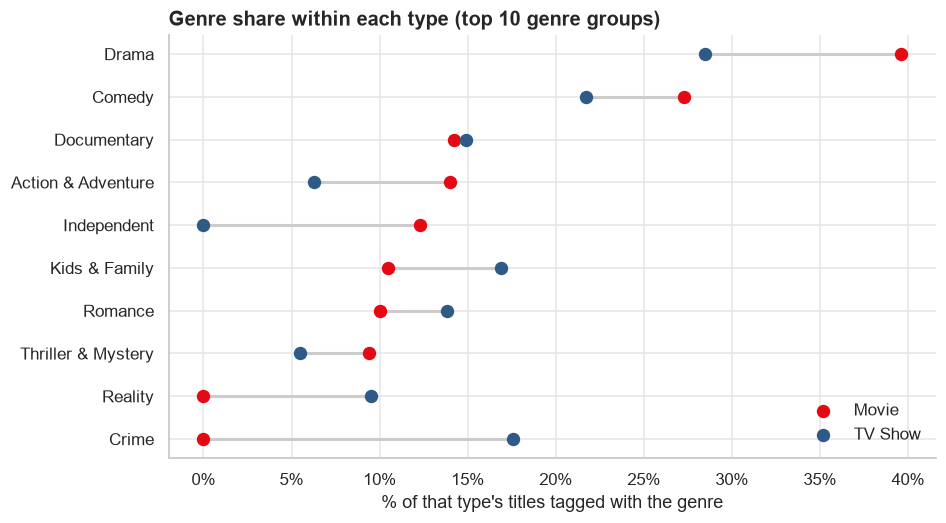

In [23]:
compare = genre_mix_by_type.loc[genre_mix_by_type[["Movie", "TV Show"]].max(axis=1).nlargest(10).index]
compare = compare.sort_values("Movie")
y = np.arange(len(compare))
fig, ax = plt.subplots(figsize=(9, 5))
ax.hlines(y, compare["Movie"], compare["TV Show"], color="#CCCCCC", linewidth=2)
ax.scatter(compare["Movie"], y, color=NETFLIX_RED, s=60, label="Movie", zorder=3)
ax.scatter(compare["TV Show"], y, color=TV_BLUE, s=60, label="TV Show", zorder=3)
ax.set_yticks(y, compare.index)
ax.xaxis.set_major_formatter(mticker.PercentFormatter(decimals=0))
ax.set_title("Genre share within each type (top 10 genre groups)")
ax.set_xlabel("% of that type's titles tagged with the genre")
ax.legend(frameon=False, loc="lower right")
save(fig, "q9_genre_mix_by_type")
plt.show()

In [24]:
freshness = titles.groupby("type")["content_age_at_add"].agg(["median", "mean"]).round(1)
freshness["added_within_1_year_pct"] = (
    titles.assign(fresh=titles["content_age_at_add"] <= 1).groupby("type")["fresh"].mean().mul(100).round(1)
)
freshness

,median,mean,added_within_1_year_pct
type,,,
Movie,2.0,5.7,49.6
TV Show,0.0,2.3,67.4


🔍 **Finding:** The two formats have different personalities.
- **Movies** lean more towards **Drama**, **Comedy**, **Action & Adventure** and **Thriller & Mystery**.
- **TV shows** lean more towards **Kids & Family**, **Romance** and **Anime**.
- **Documentary** is almost equally common in both (~14–15%).
- TV shows are typically added the **same year** they're released (median 0 years; about two-thirds within a
  year), while movies are typically ~2 years old when added — the movie side includes more **library** titles.

⚠️ **Caveats:**
- Some Netflix labels exist for **only one format** — there is no "Crime Movies", "Reality" or "Teen" label for
  movies, and no "Independent", "Sports" or "LGBTQ" label for TV. So the 0% values for Crime/Reality (movies) and
  Independent (TV) reflect **how Netflix tags content**, not necessarily what exists. Compare only genres that
  exist on both sides.
- TV "freshness" is likely overstated because a show's `release_year` may refer to its latest season.

---
## Q10 · Which content trends can be identified over time?
🎯 Is the balance between movies and TV shows shifting? We look at the **TV share** from two angles:
by when titles were **released**, and by when they were **added** to Netflix.

In [25]:
tv_share_by_release = (
    titles.query("release_year >= 2000")
    .groupby("release_year")["type"].apply(lambda s: (s == "TV Show").mean() * 100)
)
tv_share_by_added = (
    titles.query("added_year >= 2016")
    .groupby("added_year")["type"].apply(lambda s: (s == "TV Show").mean() * 100)
)
pd.DataFrame({"tv_share_by_release_year_pct": tv_share_by_release.loc[2014:].round(1),
              "tv_share_by_added_year_pct": tv_share_by_added.round(1)})

,tv_share_by_release_year_pct,tv_share_by_added_year_pct
2014,25.1,NaN
2015,28.9,NaN
2016,27.1,41.0
2017,25.7,29.4
2018,33.1,25.0
2019,38.5,29.4
2020,45.8,31.7
2021,53.2,33.7


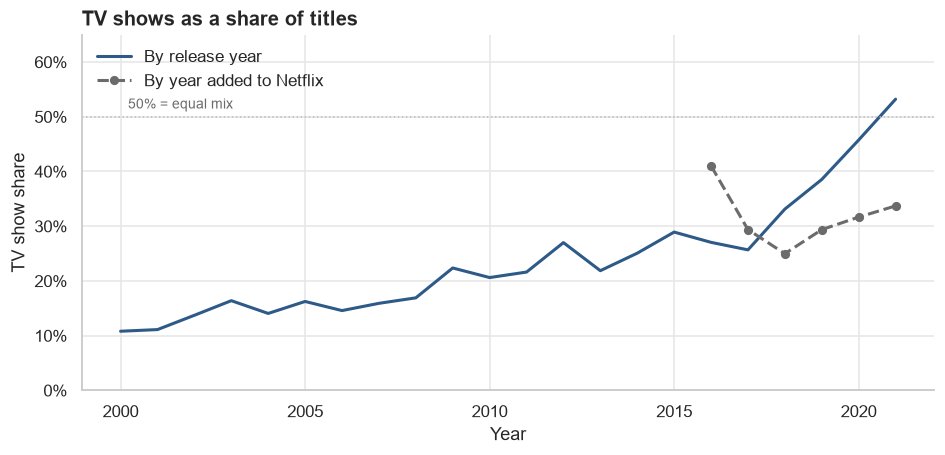

In [26]:
fig, ax = plt.subplots(figsize=(10, 4.2))
ax.plot(tv_share_by_release.index, tv_share_by_release.values, color=TV_BLUE, linewidth=2,
        label="By release year")
ax.plot(tv_share_by_added.index.astype(int), tv_share_by_added.values, color=NEUTRAL, linewidth=2,
        linestyle="--", marker="o", markersize=5, label="By year added to Netflix")
ax.axhline(50, color="#BBBBBB", linewidth=1, linestyle=":")
ax.text(2000.2, 51.5, "50% = equal mix", fontsize=9, color=NEUTRAL)
ax.yaxis.set_major_formatter(mticker.PercentFormatter())
ax.set_ylim(0, 65)
ax.set_title("TV shows as a share of titles")
ax.set_xlabel("Year")
ax.set_ylabel("TV show share")
ax.legend(frameon=False, loc="upper left")
save(fig, "q10_tv_share_trend")
plt.show()

🔍 **Finding:** Two lenses, two different stories — a great interview talking point:
- **By release year**, the TV share climbs steadily: recent releases in the catalog are far more TV-heavy than
  older ones, and 2021 releases are majority TV.
- **By year added**, the mix is much **more stable** — roughly a quarter to a third of each year's additions are
  TV shows, edging upward since 2018.

⚠️ **Caveat:** the steep release-year trend is partly a **measurement effect** (TV `release_year` may track the
latest season, and old movies are easy to license while old *TV* is less often kept). The added-year view is the
more reliable read of what Netflix actually brought in each year.

---
## Summary of what we learned

| # | Question | Short answer |
|---|---|---|
| 1 | Movies vs TV | ~70% movies, ~30% TV shows (by title count) |
| 2 | Release years | ~85% released 2010+; median release year 2017 |
| 3 | Yearly additions | Rapid growth from 2016; 2019 largest full year; 2021 YTD ahead of prior years |
| 4 | Countries | US ≈ 42% of titles, then India and UK; ~9% unknown |
| 5 | Genres | International tag on ~half; Drama, Comedy, Documentary lead |
| 6 | Ratings | TV-MA most common; adult audience largest band |
| 7 | Movie runtime | Median ≈ 98 min; ~3/4 between 60–120 min |
| 8 | TV seasons | ~2/3 have one season available |
| 9 | Content mix | Movies lean Drama/Comedy/Action; TV leans Kids, Romance, Anime; movies include more library titles |
| 10 | Trends | TV share rises sharply by release year, gently by year added |

All charts are saved in `reports/figures/`. ✅ **Phase 3 complete.** Next: SQL analysis in `sql/`.